# The advertising dataset

As a reminder, we used an [Advertising dataset](https://raw.githubusercontent.com/nguyen-toan/ISLR/master/dataset/Advertising.csv) to explore simple linear regression.

In [ ]:
# Load the Advertising dataset
import pandas as pd
url = "https://raw.githubusercontent.com/nguyen-toan/ISLR/master/dataset/Advertising.csv"
ad_df = pd.read_csv(url)

from statsmodels.formula.api import ols

# Sales is the dependent (output) variable
tv_model = ols(formula='Sales ~ TV', data=ad_df).fit()

# Show a summary of the model
tv_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Sales   R-squared:                       0.612
Model:                            OLS   Adj. R-squared:                  0.610
Method:                 Least Squares   F-statistic:                     312.1
Date:                Sat, 07 Nov 2026   Prob (F-statistic):           1.47e-42
Time:                        15:35:35   Log-Likelihood:                -519.05
No. Observations:                 200   AIC:                             1042.
Df Residuals:                     198   BIC:                             1049.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      7.0326      0.458     15.360      0.000       6.130       7.935
TV             0.0475      0.003     17.668      0.000       0.042       0.053
==============================================================================
Omnibus:                        0.531   Durbin-Watson:                   1.935
Prob(Omnibus):                  0.767   Jarque-Bera (JB):                0.669
Skew:                          -0.089   Prob(JB):                        0.716
Kurtosis:                       2.779   Cond. No.                         338.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Here are a few things we focused on linear regression results.

**The regression equation:**
*  TV coefficient - 0.0475: For every 1-unit increase in TV advertising spending, predicted sales increase by about 0.0475 units. That is, 1K more TV advertising is expected to produece 0.0475 more sales while 10K more TV advertising is expected to produce 0.475 more sales.

**Is TV an important predictor?**
*  The hypothesis is that TV spending does not matter.
*  The t value is 17.668 and p>|t| is close to 0. Therefore, we reject the null hypothesis. There is a strong evidence that TV advertising is associated with sales.

**How well does the model fit?**
*  R-squared = 0.612: about 61.2% of the variability in sales is explained by TV advertising spending. That is, about 38.8% of the variability in sales is explained by other factors.

When we perform three separate simple regressions, each model looks at only one predictor.

The coefficient measures how sales tends to change when advertising spending increases by one unit.
*  Increasing one unit on TV advertising is associated with an increase of 0.0475 unit of sales.
*  Increasing one unit on Radio advertising is associated with an increase of 0.2025 unit of sales.
*  Increasing one unit on Newspaper advertising is associated with an increase of 0.0547 unit of sales.

The R-square measures how well an advertising spending explains sales.

*  About 61.2% of the variation in sales can be explained by TV advertising spending. The remaining 39% was not explained.
*  Radio advertising spending explains about 33%.
*  Newspaper advertising spending explains about 5%.

This tells us that TV is the best predictor. It's important to note that it's a coincident that R-squares for the three model adds to be close to 1. But the three simple linear regressions were performed independently.

## Multiple linear regression for the advertising dataset

A multiple linear regression allows researchers to evalution the effect of  **multiple independent variables** in the same model. This is illustrated in the following code block.

In [ ]:
from statsmodels.formula.api import ols

# Sales is the dependent (output) variable
tv_radio_model = ols(formula='Sales ~ TV + Radio', data=ad_df).fit()

# Show a summary of the model
tv_radio_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Sales   R-squared:                       0.897
Model:                            OLS   Adj. R-squared:                  0.896
Method:                 Least Squares   F-statistic:                     859.6
Date:                Sat, 07 Nov 2026   Prob (F-statistic):           4.83e-98
Time:                        15:37:46   Log-Likelihood:                -386.20
No. Observations:                 200   AIC:                             778.4
Df Residuals:                     197   BIC:                             788.3
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.9211      0.294      9.919      0.000       2.340       3.502
TV             0.0458      0.001     32.909      0.000       0.043       0.048
Radio          0.1880      0.008     23.382      0.000       0.172       0.204
==============================================================================
Omnibus:                       60.022   Durbin-Watson:                   2.081
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              148.679
Skew:                          -1.323   Prob(JB):                     5.19e-33
Kurtosis:                       6.292   Cond. No.                         425.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

From the three simple linear regression models, we knew that TV was the best predictor and explained about 61.2% of sales. This new model shows a big increase of R-square, from 0.612 to 0.897 when we combine TV and Radio advertisement. Last week, we saw that the correlation between TV and Radio was 0.055, indicating the two spendings were quite independent. That also explains why adding radio contributes a lot of new information, i.e. from 61.2% to 89.7%.

Now, let's add newspaper into the model to if it adds any new information.

In [ ]:
from statsmodels.formula.api import ols

# Sales is the dependent (output) variable
ad_model = ols(formula='Sales ~ TV + Radio + Newspaper', data=ad_df).fit()

# Show a summary of the model
ad_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Sales   R-squared:                       0.897
Model:                            OLS   Adj. R-squared:                  0.896
Method:                 Least Squares   F-statistic:                     570.3
Date:                Sat, 07 Nov 2026   Prob (F-statistic):           1.58e-96
Time:                        08:37:34   Log-Likelihood:                -386.18
No. Observations:                 200   AIC:                             780.4
Df Residuals:                     196   BIC:                             793.6
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.9389      0.312      9.422      0.000       2.324       3.554
TV             0.0458      0.001     32.809      0.000       0.043       0.049
Radio          0.1885      0.009     21.893      0.000       0.172       0.206
Newspaper     -0.0010      0.006     -0.177      0.860      -0.013       0.011
==============================================================================
Omnibus:                       60.414   Durbin-Watson:                   2.084
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              151.241
Skew:                          -1.327   Prob(JB):                     1.44e-33
Kurtosis:                       6.332   Cond. No.                         454.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

From R-square of the new model, we can see that adding newspaper basically added no change to R-square. This illustrate that it's not necessary to keep adding every available predictor.

## Visualization

We can generate the fitted values from the model and compare them against the original observed sales.

In [ ]:
ad_df["Fitted_Sales"] = tv_radio_model.fittedvalues
ad_df[['Sales', 'Fitted_Sales']].head()

,Sales,Fitted_Sales
0,22.1,20.555465
1,10.4,12.345362
2,9.3,12.337018
3,18.5,17.617116
4,12.9,13.223908


We can see that this multiple linear regression model does a better job predicting sales than the simple linear regression models we created before.

It is hard to visualize a linear regression model when there are multiple independent variables. However, we can use a scatter plot to visualize the relationship between the actual Sales and the fitted sales.

The following code block is to generate a scatter plot to have each point reflecting one row of the dataset

*  The x-axis is for the actual observed sales in the original dataset.
*  The y-axis is for the sale values predicted by the regressiona model

If a model predicted every observation perfectly, we would expect the fitted sales be the same as the actual observed sales for all dots. That is, every point would like exactly on a 45-degree diagnal line running from the lower-left corner to the upper-right corner.

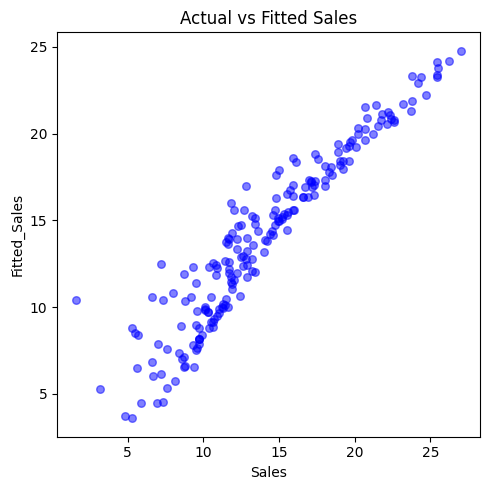

In [ ]:
import matplotlib.pyplot as plt
ad_df['Fitted_Sales'] = tv_radio_model.fittedvalues
# Plot Actual vs Predicted
ad_df.plot(kind='scatter',    #Indicate the kind of plot to be generated
        x='Sales',                  #Identify the column for the x-axis
        y='Fitted_Sales',           #Identify the column for the y_axis
        figsize=(5, 5),             #Set up the width and height of the graph
        title='Actual vs Fitted Sales',    #Set up the title of the graph
        s=30,                       #Indicate the size of each dot
        alpha=0.5,                  #Indicate the level of transparency
        color='blue'                #Indicate the color for the dots
        )

plt.tight_layout()
plt.show()



The above scatter plot shows that many of the dots are near a 45-degree line. That's evidence that the model's predictions are very close to the actual values. This is consistent with the R-square value of 0.897. A high R-square typically produces points clustered tightly along the diagonal. A low R-square would produce a much wider scatter.

The vertical distance between a dot and a perfect 45-degree line corresponds to the prediction error (residual). The model also keeps track of the residuals for all rows.

In [ ]:
ad_df['Residuals'] = tv_radio_model.resid
ad_df[['Sales', 'Fitted_Sales', 'Residuals']].head()

,Sales,Fitted_Sales,Residuals
0,22.1,20.555465,1.544535
1,10.4,12.345362,-1.945362
2,9.3,12.337018,-3.037018
3,18.5,17.617116,0.882884
4,12.9,13.223908,-0.323908


We can see from the above results that residuals are created by Sales - Fitted_Sales.

*  A positive residual occurs when the model underpredicted sales.
*  A negative residual occurs when the model overpredicted sales.
*  A zero residual indicates perfect prediction.

Another useful visualization is to plot residuals against fitted values. For a good linear model, we would like the points to look like a random cloud around zero with no obvious patterns, spread equally across the x-axis as well as above/below zero.

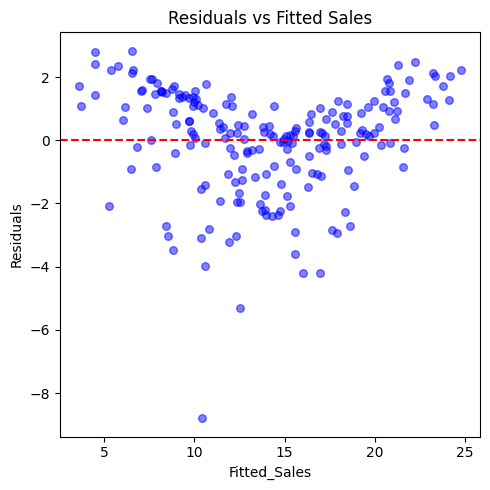

In [ ]:
import matplotlib.pyplot as plt

# Plot Actual vs Predicted
ad_df.plot(kind='scatter',    #Indicate the kind of plot to be generated
        x='Fitted_Sales',                  #Identify the column for the x-axis
        y='Residuals',           #Identify the column for the y_axis
        figsize=(5, 5),             #Set up the width and height of the graph
        title='Residuals vs Fitted Sales',    #Set up the title of the graph
        s=30,                       #Indicate the size of each dot
        alpha=0.5,                  #Indicate the level of transparency
        color='blue'                #Indicate the color for the dots
        )

plt.axhline(0, color='red', linestyle='--') # a horizontal line at 0
plt.tight_layout()
plt.show()



We can see a clear curved (U-shaped) structure in the above plot.

*  Residuals are mostly positive at low fitted values (around 5 - 10). That is, the model under predicted.
*  Residuals become mostly negative in the middle range (around 13 - 18). That is, the model over predicted.
*  Residuals trend positive again at high fitted values (around 20 - 25). That is, the model under predicted again.

The curved pattern in the residuals vs fitted plot suggests the relationship is not fully linear and that the model is systematically under and over predicting in different regions.

# Practice: The world happiness dataset

In HWK9, you analyzed data from the World Happiness Report to create correlation matrix, heatmap, and simple linear regression. As a reminder, respondents are asked to rate their lives on a scale from 0 to 10, where 0 represents the worst possible life and 10 represents the best possible life. The average rating for each country is reported as a happiness score.


Run the following code block to collect data from a [simplified CSV file](https://raw.githubusercontent.com/qarnac/cs201/refs/heads/main/world_happiness_report.csv) I created.

In [ ]:
import pandas as pd
url = "https://raw.githubusercontent.com/qarnac/cs201/refs/heads/main/world_happiness_report.csv"
df = pd.read_csv(url)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149 entries, 0 to 148
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Country name        149 non-null    object 
 1   Regional indicator  149 non-null    object 
 2   Happiness           149 non-null    float64
 3   GDP                 149 non-null    float64
 4   Social_support      149 non-null    float64
 5   Life_expectancy     149 non-null    float64
 6   Freedom             149 non-null    float64
 7   Generosity          149 non-null    float64
 8   Corruption          149 non-null    float64
dtypes: float64(7), object(2)
memory usage: 10.6+ KB


Through HWK 9, we learned the following correlations between happiness and respective variables.

*  GPD: 0.79, R-square for simple linear regression is 0.62.
*  Social_support: correlation is 0.76, R-square is 0.58.
*  Life_expectancy: correlation is 0.77, R-square is 0.59.
*  Freedom: correlation is 0.61, R-square is 0.37.
*  Corruption: correlation is -0.42, R-quare is 0.18
*  Generosity: correlation is -0.018, R-square is almost none.

For a simple linear regression between happiness and one predictor, the R-square is the square of their correlation. That is:

*  GPD: 0.79 * 0.79 -> approximately 62.4% of the variation in happiness can be explained by GPD alone.
*  Social_support: 0.76 * 0.76 -> approximately 57.8% of the variation in happiness can be explained by social support alone.
*  Life_expectancy: 0.77 * 0.77 -> approximately 59.3% of the variation in happiness can be explained by life expectancy.
*  Freedom: 0.61 * 0.61 -> approximately 37.2% of the variation in happiness can be explained by freedom alone.
*  Corruption: (-0.42) * (-0.42) -> approximately 17.6% of the variation in happiness can be explained by corruption.
*  Generosity: (-0.018) * (-0.018) -> 0.000324, nearly none of the variation in happiness can be explained by generosity.

As mentioned earlier, it was purely a coincidence that the R-square values for TV, Radio, and Newspaper happened to add up to nearly 1 in the advertising dataset. It should not be interpreted as each predictor explaining a separate portion of the variation in Sales. This is obvious for the happiness dataset.

## Multiple linear regressions

In this activity, you will investigate how adding predictors affects a model's ability to explain variation in happiness.

*  Begin with a multiple linear regression model that includes GDP and one additional predictor of your choice, e.g. Social_support, Life_expectancy, Freedom, Generosity, Corruption
*  Create a second model by adding one more predictor that was not included in your first model.

In [ ]:
# Build the first multiple linear regression model between Happiness and GDP with predictor A


In [ ]:
# Build the second multiple linear regression model between Happiness and GDP with predictor A and predictor B


**Add a text block** to compare the two models and discuss how the additional predictor affected model performance. For example,

*  Compare the R-square values of the two models. Determine whether the increase was substantial or relatively small.
*  Does the additional predictor appear to provide useful information beyond the predictors already included in the model? Use the correlation among the variables to explain your results. Consider whether the newly added predictor may provide new information or whether it overlaps with information already captured by the existing predictors.

## Visualization


For last multiple linear regression model, generate two scatter plots

*  One between the actual happiness and fitted happiness
*  Another between residuals and fitted happiness


In [ ]:
#  scatter plot between actual happiness and fitted happiness


In [ ]:
# scatter plot between residuals and fitted happiness


**Add a text block** to explain what the visualizations tell you about the model.

*  Does the the Observed vs. Fitted plotmodel appear to predict happiness accurately? Support your answer using evidence from the plot.
*  Are the residuals randomly scattered around zero, or do you notice any patterns that suggest the model may not be perfect?